<a href="https://colab.research.google.com/github/summerof69/marketing-channel-attribution/blob/main/notebooks/attribution_1_what_is_marketing_attribution_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Marketing Channel Attribution, Part 1: What is marketing attribution?

 - Python notebook for **Part 1** of the series.
 - It regenerates the dummy journeys for **Kesari Threads** (fictional D2C ethnic-wear brand) and **TaskHarbor** (fictional B2B SaaS) and every data figure (except Figure 1) in Part 1.
 - All companies and numbers are fictional and seeded, so every run reproduces the blog exactly.

## 1.Channels, journey generator and attribution models

- Every report uses the two funnel stages in Part 1
- **TOF** (top of funnel) is every touch up to the moment of intent, which is add to cart at Kesari Threads and the demo request at TaskHarbor
- **BOF** (bottom of funnel) is everything after it. The generator also gives each channel a journey role (opener, nurture or closer). That role only decides where a channel tends to appear in a simulated journey; it is never used in a report.
- TaskHarbor is simulated in USD and converted to INR at a fixed ₹80 per USD, so every amount in the series is in rupees. Each model takes one ordered journey and returns credit weights that add up to 1.

In [ ]:
from __future__ import annotations

from collections import defaultdict

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Channel definitions
# ---------------------------------------------------------------------------
#   Funnel stage used in every report, as defined in Part 1 of the series:
#   TOF (top of funnel)    = touches up to the moment of intent
#                            (add to cart at Kesari, the demo request at TaskHarbor)
#   BOF (bottom of funnel) = touches after it

D2C_CHANNELS = {
    "Instagram Ads":   "TOF",
    "YouTube":         "TOF",
    "Influencer":      "TOF",
    "Google Shopping": "TOF",
    "Email":           "BOF",   # grouped with BOF, following Part 1's cart-reminder example
    "Brand Search":    "BOF",
    "Direct":          "BOF",
}

B2B_CHANNELS = {
    "LinkedIn Ads":    "TOF",
    "Content / SEO":   "TOF",
    "Webinar":         "TOF",
    "Review Sites":    "TOF",
    "Email Nurture":   "TOF",   # nurture emails go to leads before the demo request
    "Brand Search":    "BOF",
    "Direct":          "BOF",
}

# Journey role, used only by the generator to place channels realistically:
# openers tend to start a journey, closers tend to end it, nurture sits between.
D2C_ROLES = {
    "Instagram Ads": "opener", "YouTube": "opener", "Influencer": "opener",
    "Google Shopping": "nurture", "Email": "nurture",
    "Brand Search": "closer", "Direct": "closer",
}
B2B_ROLES = {
    "LinkedIn Ads": "opener", "Content / SEO": "opener",
    "Webinar": "nurture", "Review Sites": "nurture", "Email Nurture": "nurture",
    "Brand Search": "closer", "Direct": "closer",
}

USD_TO_INR = 80  # TaskHarbor is simulated in USD, then reported in INR at a fixed rate

# Media / programme spend per channel for the period the journeys cover (illustrative).
# Direct has no spend. Brand Search is cheap because people already know you.
D2C_SPEND_INR = {
    "Instagram Ads": 900_000, "YouTube": 600_000, "Influencer": 500_000,
    "Google Shopping": 700_000, "Email": 100_000, "Brand Search": 200_000,
    "Direct": 0,
}
B2B_SPEND_INR = {  # annual programme spend for the same period as the 600 deals
    ch: usd * USD_TO_INR for ch, usd in {
        "LinkedIn Ads": 900_000, "Content / SEO": 400_000, "Webinar": 300_000,
        "Review Sites": 200_000, "Email Nurture": 80_000, "Brand Search": 150_000,
        "Direct": 0,
    }.items()
}


# ---------------------------------------------------------------------------
# 2. Journey generator
# ---------------------------------------------------------------------------
def _pick(rng, roles: dict, role: str, weights: dict | None = None) -> str:
    names = [c for c, r in roles.items() if r == role]
    p = np.array([weights.get(c, 1.0) if weights else 1.0 for c in names])
    return rng.choice(names, p=p / p.sum())


def generate_journeys(
    business: str = "d2c", n: int = 2000, seed: int = 42
) -> pd.DataFrame:
    """Return one row per touchpoint of converting journeys.

    Columns: journey_id, step, channel, stage, days_before_conversion, revenue
    Journeys follow a realistic shape: they usually *start* with opener
    channels (social, video, LinkedIn), pass through nurture channels and *end*
    on closers such as Brand Search or Direct. The `stage` column holds the
    TOF/BOF reporting stage. Revenue is INR for both companies.
    """
    rng = np.random.default_rng(seed)
    if business == "d2c":
        channels, roles = D2C_CHANNELS, D2C_ROLES
        mean_extra_touches, max_days = 2.0, 21
        tof_w = {"Instagram Ads": 3, "YouTube": 1.5, "Influencer": 1.5}
        mof_w = {"Google Shopping": 2, "Email": 1.5}
        bof_w = {"Brand Search": 1.3, "Direct": 1.0}
    elif business == "b2b":
        channels, roles = B2B_CHANNELS, B2B_ROLES
        mean_extra_touches, max_days = 6.0, 120
        tof_w = {"LinkedIn Ads": 2.5, "Content / SEO": 1.5}
        mof_w = {"Webinar": 1.2, "Review Sites": 1.0, "Email Nurture": 2.0}
        bof_w = {"Brand Search": 1.2, "Direct": 1.0}
    else:
        raise ValueError("business must be 'd2c' or 'b2b'")

    rows = []
    for j in range(n):
        n_touch = 1 + rng.poisson(mean_extra_touches)
        path = []
        for k in range(n_touch):
            pos = k / max(n_touch - 1, 1)  # 0 = first touch, 1 = last touch
            if n_touch == 1:
                stage_p = [0.25, 0.25, 0.50]  # single-touch: mostly intent
            elif k == 0:
                stage_p = [0.75, 0.20, 0.05]
            elif k == n_touch - 1:
                stage_p = [0.05, 0.20, 0.75]
            else:
                stage_p = [0.45 * (1 - pos) + 0.10,
                           0.55,
                           0.45 * pos - 0.10 + 0.0]
                stage_p = np.clip(stage_p, 0.02, None)
                stage_p = stage_p / stage_p.sum()
            role = rng.choice(["opener", "nurture", "closer"], p=stage_p)
            w = {"opener": tof_w, "nurture": mof_w, "closer": bof_w}[role]
            path.append(_pick(rng, roles, role, w))

        # days before conversion: first touch is oldest, last touch is day 0
        span = rng.uniform(0.2, 1.0) * max_days
        days = np.sort(rng.uniform(0, span, n_touch))[::-1]
        days[-1] = 0.0

        if business == "d2c":  # order value in INR
            revenue = float(np.round(rng.lognormal(np.log(2400), 0.45), -1))
        else:                  # first-year ARR, simulated in USD and reported in INR
            revenue = float(np.round(rng.lognormal(np.log(9000), 0.6), -2)) * USD_TO_INR

        for k, ch in enumerate(path):
            rows.append({
                "journey_id": f"{business.upper()}-{j:05d}",
                "step": k + 1,
                "channel": ch,
                "stage": channels[ch],
                "days_before_conversion": round(float(days[k]), 1),
                "revenue": revenue,
            })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# 3. Attribution models
# ---------------------------------------------------------------------------
# Every model takes one journey (an ordered list of channels, plus optional
# days-before-conversion) and returns {channel: weight}, weights summing to 1.

def first_touch(path, days=None):
    return {path[0]: 1.0}


def last_click(path, days=None):
    """Last click (LC), also called last touch: the final touchpoint gets everything."""
    return {path[-1]: 1.0}


def last_non_direct(path, days=None, direct="Direct"):
    """Last Non-Direct Click: like last click (LC), but skips Direct visits.
    If the whole journey is Direct, Direct keeps the credit."""
    non_direct = [c for c in path if c != direct]
    return {(non_direct[-1] if non_direct else direct): 1.0}


def linear(path, days=None):
    w = defaultdict(float)
    for c in path:
        w[c] += 1.0 / len(path)
    return dict(w)


def position_based(path, days=None, first=0.4, last=0.4):
    """U-shaped: 40% first touch, 40% last touch, 20% spread over the middle."""
    n = len(path)
    if n == 1:
        return {path[0]: 1.0}
    if n == 2:
        w = defaultdict(float)
        w[path[0]] += 0.5
        w[path[1]] += 0.5
        return dict(w)
    w = defaultdict(float)
    w[path[0]] += first
    w[path[-1]] += last
    middle = (1 - first - last) / (n - 2)
    for c in path[1:-1]:
        w[c] += middle
    return dict(w)


def time_decay(path, days, half_life=7.0):
    """Touches closer to conversion get more credit: weight = 2^(-days/half_life)."""
    raw = np.power(2.0, -np.asarray(days, dtype=float) / half_life)
    raw = raw / raw.sum()
    w = defaultdict(float)
    for c, r in zip(path, raw):
        w[c] += float(r)
    return dict(w)


MODELS = {
    "First touch": first_touch,
    "Last click (LC)": last_click,
    "Last non-direct": last_non_direct,
    "Linear": linear,
    "Position-based": position_based,
    "Time decay": time_decay,
}


def attribute(df: pd.DataFrame, model, value: str = "revenue") -> pd.Series:
    """Apply one model to every journey. Returns attributed value by channel.
    value='revenue' distributes money; value='conversions' distributes counts."""
    credit = defaultdict(float)
    for _, g in df.sort_values(["journey_id", "step"]).groupby("journey_id"):
        path = g["channel"].tolist()
        days = g["days_before_conversion"].tolist()
        amount = 1.0 if value == "conversions" else g["revenue"].iloc[0]
        for ch, w in model(path, days).items():
            credit[ch] += w * amount
    return pd.Series(credit)


def compare_models(df: pd.DataFrame, value: str = "revenue") -> pd.DataFrame:
    """Attributed value by channel (rows) for every model (columns)."""
    out = pd.DataFrame({name: attribute(df, fn, value) for name, fn in MODELS.items()})
    return out.fillna(0.0)


def share_table(table: pd.DataFrame) -> pd.DataFrame:
    return (table / table.sum() * 100).round(1)


def stage_share(table: pd.DataFrame, channels: dict) -> pd.DataFrame:
    """Share of credit going to TOF and BOF channels under each model."""
    st = table.groupby(table.index.map(channels)).sum()
    return (st / st.sum() * 100).round(1).reindex(["TOF", "BOF"])


def roas_table(table: pd.DataFrame, spend: dict) -> pd.DataFrame:
    """Attributed revenue / spend for each paid channel under each model."""
    s = pd.Series(spend)
    s = s[s > 0]
    return table.loc[s.index].div(s, axis=0).round(2)


def zero_credit_share(df: pd.DataFrame) -> float:
    """% of all touchpoints that get no credit under a single-touch model (LC or LNDC)."""
    return round(float((1 - df["journey_id"].nunique() / len(df)) * 100), 1)


def journey_summary(df: pd.DataFrame) -> dict:
    lengths = df.groupby("journey_id")["step"].max()
    return {
        "journeys": int(lengths.size),
        "mean_touches": round(float(lengths.mean()), 1),
        "median_touches": float(lengths.median()),
        "single_touch_pct": round(float((lengths == 1).mean() * 100), 1),
        "zero_credit_touch_pct_lc": zero_credit_share(df),
        "revenue_total": float(df.groupby("journey_id")["revenue"].first().sum()),
    }


# ---------------------------------------------------------------------------
# 4. A worked single journey (used in Part 2)
# ---------------------------------------------------------------------------
EXAMPLE_PATH = ["Instagram Ads", "Email", "Google Shopping", "Direct"]
EXAMPLE_DAYS = [14, 6, 2, 0]
EXAMPLE_REVENUE = 3000  # INR


def example_journey_split() -> pd.DataFrame:
    rows = {}
    for name, fn in MODELS.items():
        rows[name] = {ch: w * EXAMPLE_REVENUE for ch, w in fn(EXAMPLE_PATH, EXAMPLE_DAYS).items()}
    return pd.DataFrame(rows).T.reindex(columns=EXAMPLE_PATH).fillna(0).round(0)

## 2.Generate the dummy data and save it as CSV

One row per touchpoint of a converting journey.

---------------------------------------------------------------------------
Column guide: one row = one touchpoint in a journey that ended in a conversion
---------------------------------------------------------------------------
- journey_id             : ID of one customer's path to a single conversion.
                         D2C-xxxxx = a Kesari Threads order, B2B-xxxxx = a TaskHarbor deal.
                         Every row with the same journey_id belongs to the same journey.
- step                   : order of the touchpoint within its journey.
                         1 = first touch; the highest step = last touch before converting.
- channel                : the source the touchpoint came from
                         (e.g. Instagram Ads, Email, Google Shopping, Brand Search, Direct).
- stage                  : funnel stage. TOF = up to add to cart (Kesari) or the demo request
                         (TaskHarbor); BOF = after it.
- days_before_conversion : how many days before the conversion the touch happened.
                         The last touch is always 0.
- revenue                : value of the whole conversion in INR (Kesari order value, or
                         TaskHarbor first-year ARR at ₹80/USD). It repeats on every row of
                         a journey, so take one value per journey_id before summing.
- company                : Kesari Threads (fictional D2C brand) or TaskHarbor (fictional B2B SaaS).

In [ ]:
d2c = generate_journeys("d2c", n=2000, seed=42)
b2b = generate_journeys("b2b", n=600, seed=7)
data = pd.concat([d2c.assign(company="Kesari Threads"), b2b.assign(company="TaskHarbor")])
data.to_csv("attribution-1-what-is-marketing-attribution-data.csv", index=False)
data.head(8)

,journey_id,step,channel,stage,days_before_conversion,revenue,company
0,D2C-00000,1,Direct,BOF,6.6,1770.0,Kesari Threads
1,D2C-00000,2,Google Shopping,TOF,6.1,1770.0,Kesari Threads
2,D2C-00000,3,Google Shopping,TOF,5.1,1770.0,Kesari Threads
3,D2C-00000,4,Direct,BOF,4.4,1770.0,Kesari Threads
4,D2C-00000,5,Brand Search,BOF,0.0,1770.0,Kesari Threads
5,D2C-00001,1,Instagram Ads,TOF,5.8,3220.0,Kesari Threads
6,D2C-00001,2,YouTube,TOF,2.7,3220.0,Kesari Threads
7,D2C-00001,3,Email,BOF,2.3,3220.0,Kesari Threads


### 2.1Journey summary for both companies

`zero_credit_touch_pct_lc` is the share of touchpoints that get no credit under a single-touch model such as last click (LC) or LNDC.

In [ ]:
pd.DataFrame({'Kesari Threads': journey_summary(d2c), 'TaskHarbor': journey_summary(b2b)})

,Kesari Threads,TaskHarbor
journeys,2000.0,600.0
mean_touches,3.0,7.1
median_touches,3.0,7.0
single_touch_pct,13.6,0.2
zero_credit_touch_pct_lc,66.8,85.9
revenue_total,5338320.0,522584000.0


## 3.Plot settings

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.patches import FancyBboxPatch

OUT = "."  # figures are saved next to the notebook
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 12,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
})
STAGE_COL = {"TOF": "#3b82f6", "BOF": "#ef4444"}
TOUCH_COL = ["#3b82f6", "#a855f7", "#f59e0b", "#ef4444"]  # Instagram, Email, Google Shopping, Direct
LC = "Last click (LC)"
MODEL_ORDER = list(MODELS.keys())
FUNNEL_ORDER = ["Influencer", "Instagram Ads", "YouTube", "Google Shopping", "Email",
                "LinkedIn Ads", "Content / SEO", "Review Sites", "Webinar", "Email Nurture",
                "Brand Search", "Direct"]
rev_d2c = compare_models(d2c, "revenue")
rev_b2b = compare_models(b2b, "revenue")


def save(fig, name):
    """Save the figure next to the notebook and show it."""
    fig.savefig(os.path.join(OUT, name), dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 4.1 Figure 2: one ₹3,000 order credited four ways

The journey is Instagram Ads → Email → Google Shopping → Direct.

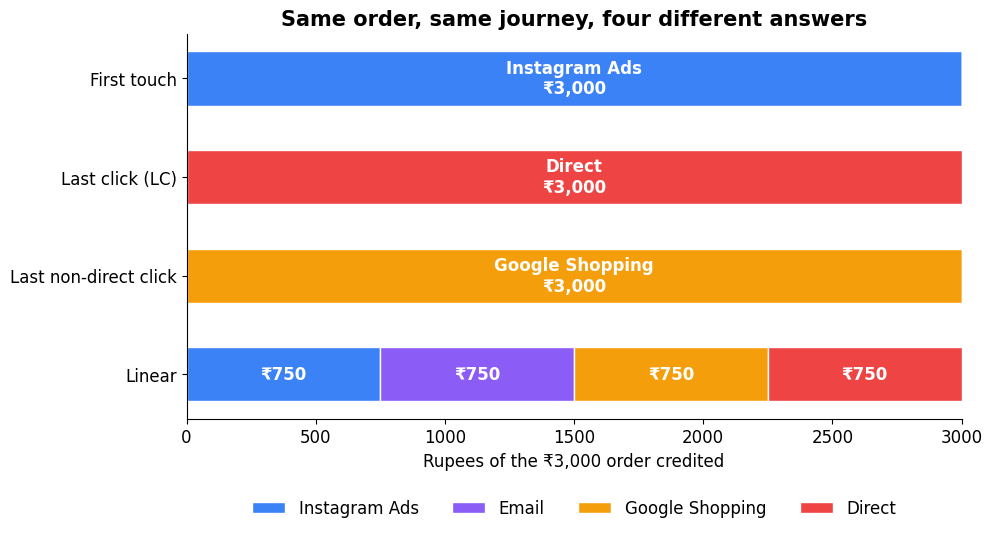

In [ ]:
def fig_same_order_four():
    """Part 1, Figure 2: one Rs 3,000 order under four models."""
    rows = ["First touch", LC, "Last non-direct click", "Linear"]
    t = example_journey_split().rename(index={"Last non-direct": "Last non-direct click"}).loc[rows]
    cols = ["#3b82f6", "#8b5cf6", "#f59e0b", "#ef4444"]
    fig, ax = plt.subplots(figsize=(10, 5))
    left = np.zeros(len(t))
    for c, col in zip(EXAMPLE_PATH, cols):
        vals = t[c].values
        ax.barh(rows, vals, left=left, color=col, label=c, height=0.55, edgecolor="white")
        for i, (v, l) in enumerate(zip(vals, left)):
            if v > 0:
                text = f"{c}\n₹{v:,.0f}" if v == EXAMPLE_REVENUE else f"₹{v:,.0f}"
                ax.text(l + v / 2, i, text, ha="center", va="center", color="white", fontsize=12, weight="bold")
        left += vals
    ax.invert_yaxis(); ax.set_xlim(0, EXAMPLE_REVENUE)
    ax.set_xlabel("Rupees of the ₹3,000 order credited")
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)
    ax.set_title("Same order, same journey, four different answers")
    save(fig, "01-same-order-four-models-lc.png")


fig_same_order_four()

## 4.2 Figure 3: touchpoints per converting journey

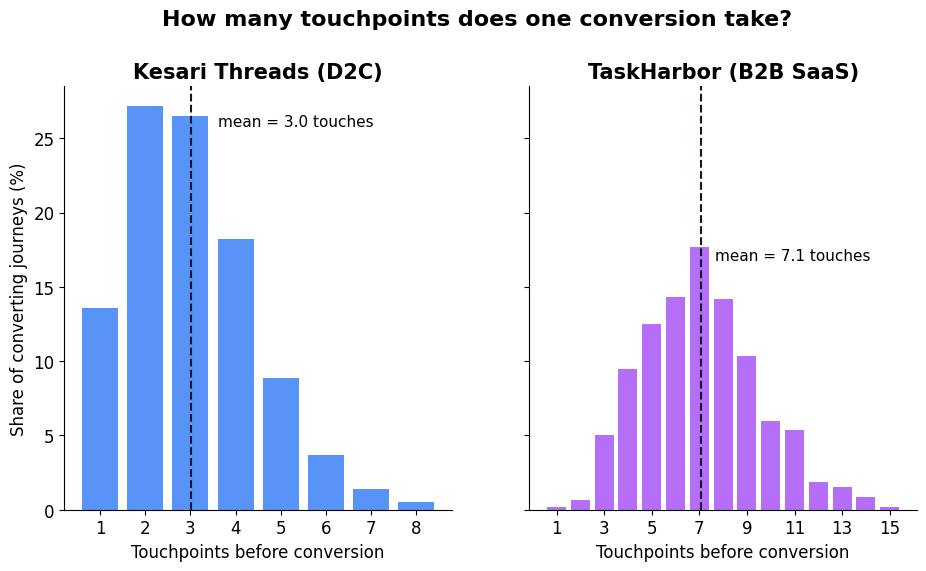

In [ ]:
def fig_journey_length():
    """Part 1, Figure 3: touchpoints per converting journey."""
    lens_d = d2c.groupby("journey_id")["step"].max()
    lens_b = b2b.groupby("journey_id")["step"].max()
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
    for ax, lens, name, col in [(axes[0], lens_d, "Kesari Threads (D2C)", "#3b82f6"),
                                (axes[1], lens_b, "TaskHarbor (B2B SaaS)", "#a855f7")]:
        counts = lens.value_counts(normalize=True).sort_index() * 100
        ax.bar(counts.index, counts.values, color=col, alpha=0.85)
        ax.axvline(lens.mean(), color="#0f172a", ls="--", lw=1.5)
        ax.text(lens.mean() + 0.6, counts.max() * 0.95, f"mean = {lens.mean():.1f} touches", fontsize=11, bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))
        ax.set_title(name)
        ax.set_xlabel("Touchpoints before conversion")
        ax.set_xticks(range(1, int(lens.max()) + 1, 1 if lens.max() < 12 else 2))
    axes[0].set_ylabel("Share of converting journeys (%)")
    fig.suptitle("How many touchpoints does one conversion take?", fontsize=16, weight="bold", y=1.02)
    save(fig, "01-journey-length-d2c-vs-b2b.png")


fig_journey_length()

## 4.3 Shared helper: one journey on a timeline, split into TOF and BOF

In [ ]:
def inr_short(v):
    """Format rupees the Indian way: 1,120,000 -> 11.2 lakh."""
    return f"₹{v / 1e7:.1f} crore" if v >= 1e7 else f"₹{v / 1e5:.1f} lakh" if v >= 1e5 else f"₹{v:,.0f}"


def journey_timeline(ax, days, labels, boundary, tof_note, bof_note, value_label, title, right):
    """One journey on a day axis with the TOF/BOF split shaded (Part 1, Figures 4 and 5)."""
    x = -np.asarray(days, dtype=float)
    lo, hi = x.min() - 3, right
    ax.axvspan(lo, boundary, color="#eff6ff", zorder=0)
    ax.axvspan(boundary, hi, color="#fef2f2", zorder=0)
    ax.axvline(boundary, color="#475569", ls="--", lw=1.6)
    ax.plot([x.min() - 2, hi * 0.65], [0, 0], color="#94a3b8", lw=3.5, zorder=1)
    for k, (xi, lab) in enumerate(zip(x, labels)):
        ax.scatter(xi, 0, s=420, color=STAGE_COL["TOF" if xi < boundary else "BOF"],
                   edgecolor="white", linewidth=2, zorder=2)
        ax.annotate(lab, (xi, 0), xytext=(0, 32 if k % 2 == 0 else -40), textcoords="offset points",
                    ha="center", va="center", fontsize=12)
    star_x = hi * 0.5
    ax.scatter(star_x, 0, s=700, marker="*", color="#22c55e", zorder=3)
    ax.annotate(value_label, (star_x, 0), xytext=(0, -48), textcoords="offset points",
                ha="center", va="center", fontsize=12, weight="bold", color="#15803d")
    for xm, head, note, col in [((lo + boundary) / 2, "TOF: top of funnel", tof_note, "#1d4ed8"),
                                ((boundary + hi) / 2, "BOF: bottom of funnel", bof_note, "#b91c1c")]:
        ax.text(xm, 0.78, head, ha="center", fontsize=14, weight="bold", color=col)
        ax.text(xm, 0.66, note, ha="center", fontsize=11.5, color="#475569")
    ax.set_xlim(lo, hi); ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_title(title)

## 4.4 Figure 4: one ₹8,500 Kesari Threads order

This journey is **illustrative**: it is written out by hand to explain add to cart, not drawn from the simulated data.

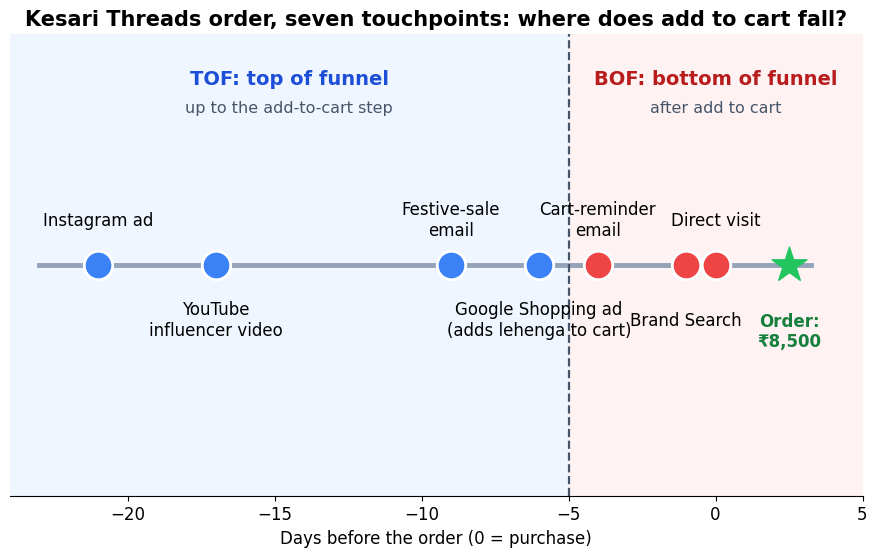

In [ ]:
KESARI_EXAMPLE = [
    ("Instagram ad", 21), ("YouTube\ninfluencer video", 17), ("Festive-sale\nemail", 9),
    ("Google Shopping ad\n(adds lehenga to cart)", 6), ("Cart-reminder\nemail", 4),
    ("Brand Search", 1), ("Direct visit", 0),
]


def fig_kesari_journey():
    """Part 1, Figure 4: one Rs 8,500 Kesari order split at add to cart (illustrative journey)."""
    labels, days = zip(*KESARI_EXAMPLE)
    fig, ax = plt.subplots(figsize=(11, 6))
    journey_timeline(ax, days, labels, boundary=-5, tof_note="up to the add-to-cart step",
                     bof_note="after add to cart", value_label="Order:\n₹8,500",
                     title="Kesari Threads order, seven touchpoints: where does add to cart fall?", right=5)
    ax.set_xlabel("Days before the order (0 = purchase)")
    save(fig, "01-kesari-journey-tof-bof.png")


fig_kesari_journey()

## 4.5 Figure 5: one ₹11.2 lakh TaskHarbor deal

This deal is picked from the simulated data. BOF starts at the Direct visit that books the demo.

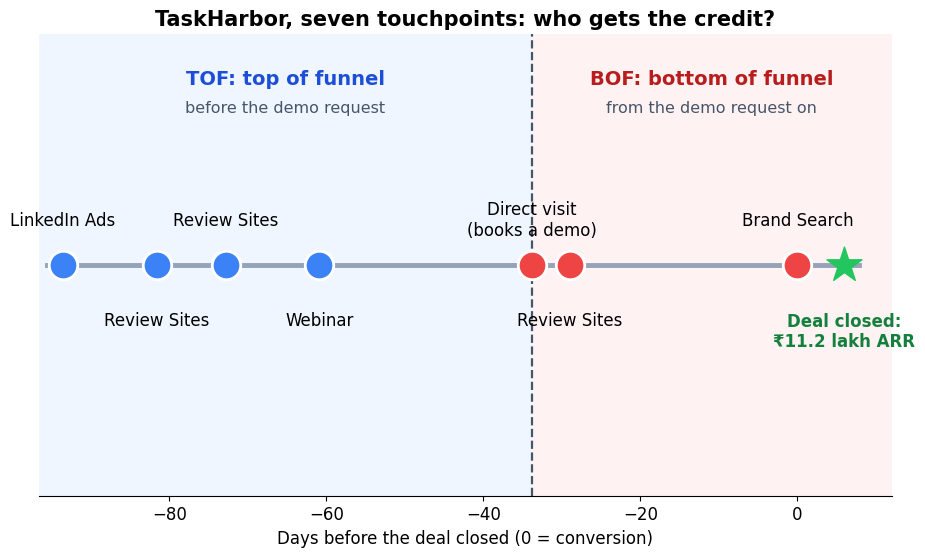

,step,channel,days_before_conversion,revenue
223,1,LinkedIn Ads,93.6,1120000.0
224,2,Review Sites,81.6,1120000.0
225,3,Review Sites,72.8,1120000.0
226,4,Webinar,60.9,1120000.0
227,5,Direct,33.8,1120000.0
228,6,Review Sites,29.0,1120000.0
229,7,Brand Search,0.0,1120000.0


In [ ]:
def pick_taskharbor_example():
    """The first 7-touch deal that starts on LinkedIn, ends on Brand Search or Direct and is worth >= Rs 6.4 lakh."""
    for jid, j in b2b.groupby("journey_id"):
        ch = j["channel"].tolist()
        if (len(ch) == 7 and ch[0] == "LinkedIn Ads" and ch[-1] in ("Direct", "Brand Search")
                and len(set(ch)) >= 5 and j["revenue"].iloc[0] >= 8000 * 80):
            return jid, j.sort_values("step")


def fig_taskharbor_journey():
    """Part 1, Figure 5: the Rs 11.2 lakh TaskHarbor deal, split at the demo request."""
    jid, j = pick_taskharbor_example()
    days = j["days_before_conversion"].tolist()
    labels = j["channel"].tolist()
    demo = labels.index("Direct")          # the Direct visit that books the demo starts BOF
    labels[demo] = "Direct visit\n(books a demo)"
    boundary = -days[demo]
    fig, ax = plt.subplots(figsize=(11, 6))
    journey_timeline(ax, days, labels, boundary=boundary - 0.01, tof_note="before the demo request",
                     bof_note="from the demo request on",
                     value_label=f"Deal closed:\n{inr_short(j['revenue'].iloc[0])} ARR",
                     title="TaskHarbor, seven touchpoints: who gets the credit?", right=12)
    ax.set_xlabel("Days before the deal closed (0 = conversion)")
    save(fig, "01-taskharbor-journey-tof-bof.png")
    return jid, j


jid, deal = fig_taskharbor_journey()
deal[['step', 'channel', 'days_before_conversion', 'revenue']]

### Who gets the ₹11.2 lakh under each single-touch rule?

In [ ]:
path = deal['channel'].tolist()
pd.DataFrame({name: fn(path) for name, fn in [('First touch', first_touch), ('Last click (LC)', last_click),
                                              ('Last non-direct', last_non_direct)]}).fillna(0).mul(deal['revenue'].iloc[0])

,First touch,Last click (LC),Last non-direct
LinkedIn Ads,1120000.0,0.0,0.0
Brand Search,0.0,1120000.0,1120000.0
